# Zachary Weed

# [Problem 1] - Implementing an MLFlow Server

#### Problem Statement

**Problem 1**. Install the `mlflow` software locally on your Mac/Windows/Linux machine. Do it inside the `cuda` virtual environment you use to run Pytorch notebooks. Choose on directory and open a command prompt in that directory. Keep using that one directory to start your `mlflow` servers.

- Start `mlflow UI` on port 5000 and convince yourself that the setup is working by examining MLFlow UI at (http:127.0.0.1:5000/). At this time the UI should be empty.
- Run the `pytorch_tracking.ipynb` notebook. The notebook was discussed in the lecture. Run the notebook 3 times. Every time change some parameters. Capture the screenshot of the UI of the tracking server demonstrating that the experiment is registered by the server. Demonstrate that logged metrics and artifacts are appearing on the server.
- Tell us the content of `conda.yaml` and `python_env.yaml` files.
- Demonstrate that you can run one of the models saved on the MLFlow server and make predictions with that model.
- Examine the content of the directory in which you started your tracking server. Briefly report on the content of that directory. Compare the content of the directory with the display on port 5000. Brief description is sufficient.

### Defines an Experiment Factory

In [ ]:
import mlflow

class ExperimentFactory():
    def __init__(self, experiment_name, ml_flow_url):
        self.experiment_name = experiment_name
        self.ml_flow_url = ml_flow_url

    def build(self):
        mlflow.set_tracking_uri(self.ml_flow_url)
        mlflow.set_experiment(self.experiment_name)
        mlflow.config.enable_system_metrics_logging()
        mlflow.config.set_system_metrics_sampling_interval(1)

### Handles Installation of MLFlow

In [7]:
# Installation of mlflow
!pip install mlflow --quiet


[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: pip install --upgrade pip


### Starts MLFlow Server for Tracking

In [14]:
!mlflow server --host 127.0.0.1 --port 5000

Backend store URI not provided. Using sqlite:///mlflow.db
Registry store URI not provided. Using backend store URI.
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.schemas
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.tables
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.types
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.constraints
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.defaults
2026/02/20 19:59:29 INFO alembic.runtime.plugins: setup plugin alembic.autogenerate.comments
2026/02/20 19:59:29 INFO alembic.runtime.migration: Context impl SQLiteImpl.
2026/02/20 19:59:29 INFO alembic.runtime.migration: Will assume non-transactional DDL.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts 

### Post Experiment Creation

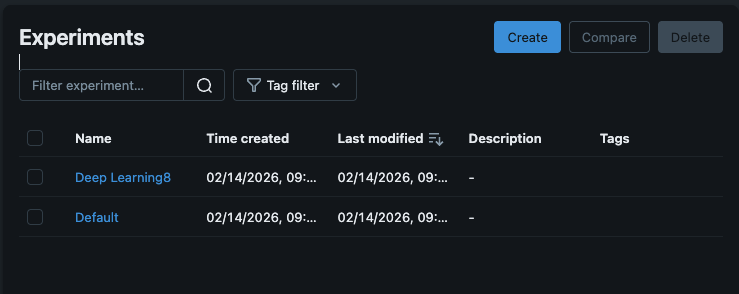

In essence, this identifies what MLFlow looked like after importing the notebook.

### Indication Results are Logged

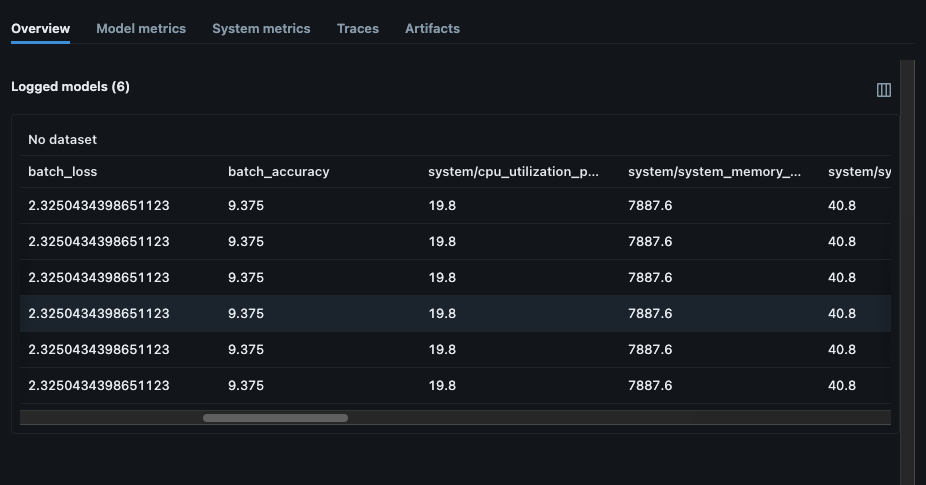

Here we have the results of the model

### Model Metrics - 5 Epochs & SGD

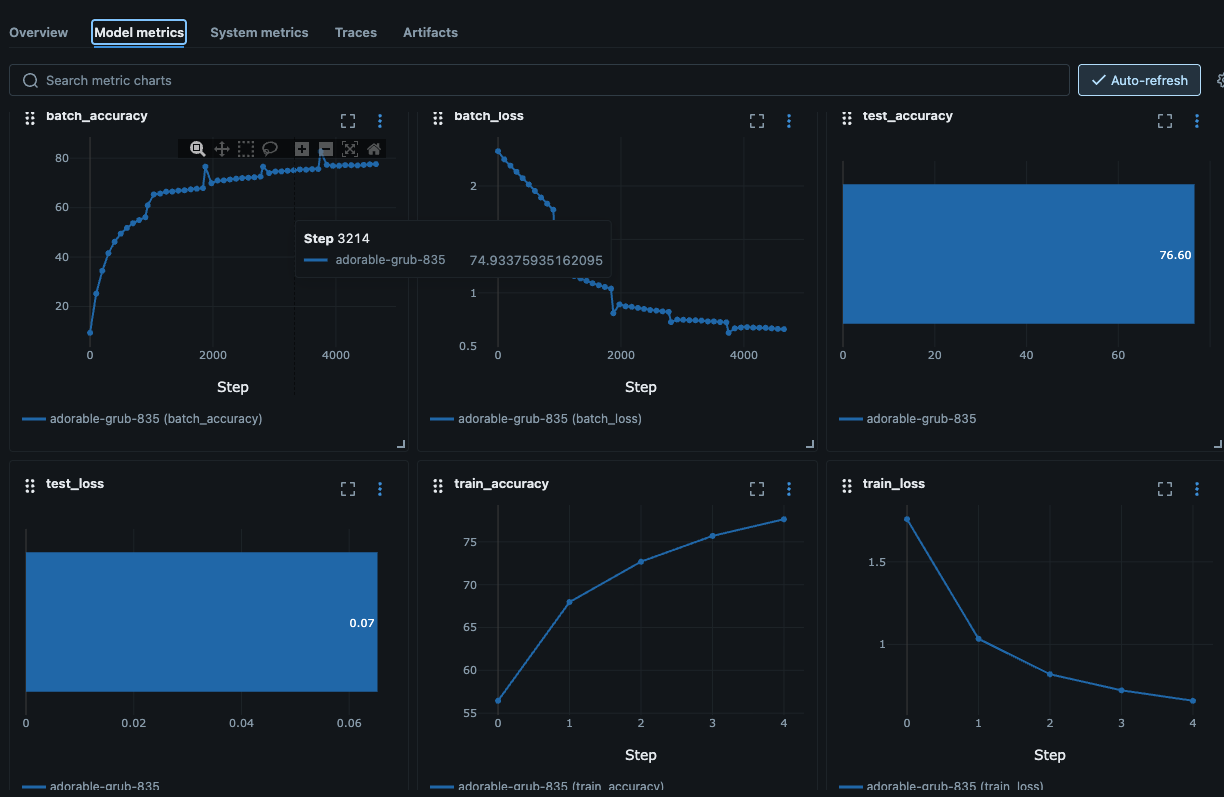

Relatively straightforward, these are our metrics with 5 Epochs and SGD.

### Model Metrics - 6 Epochs & SGD

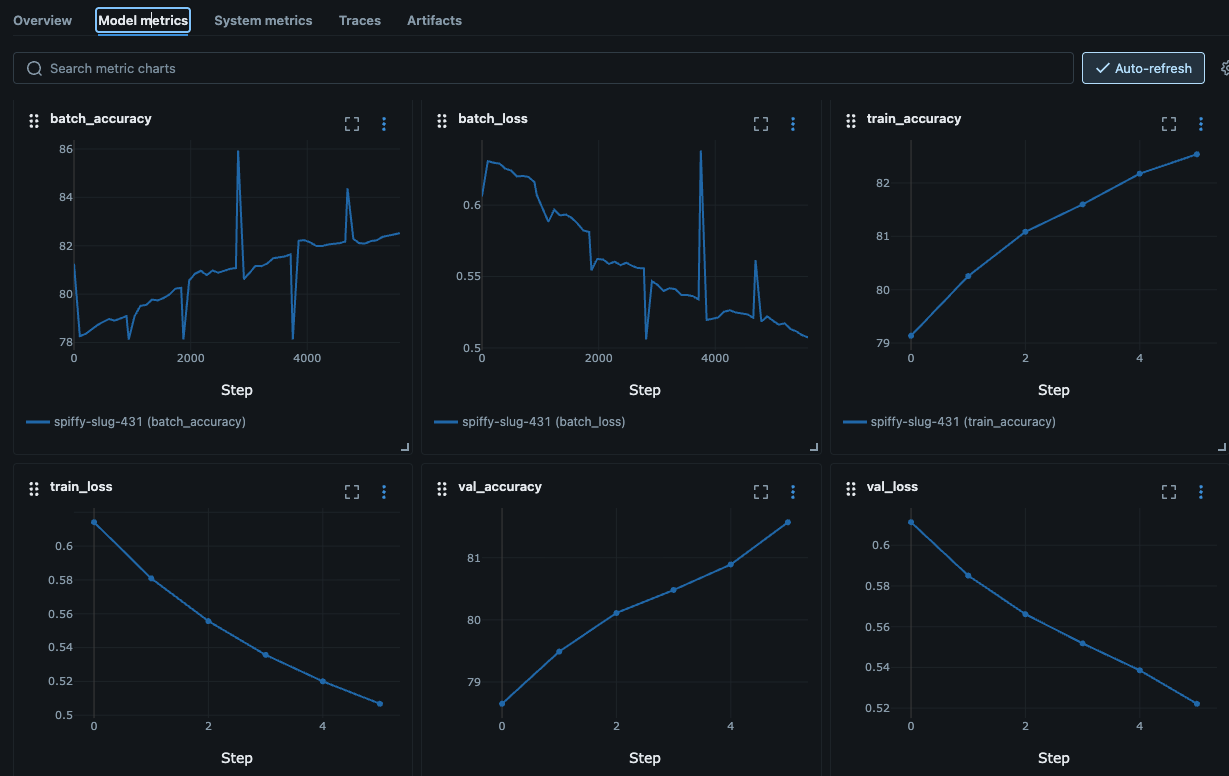

Similarly, here we have metrics with SGD, and 6 epochs

### Model Metrics - 6 Epochs & Adam Optimizer

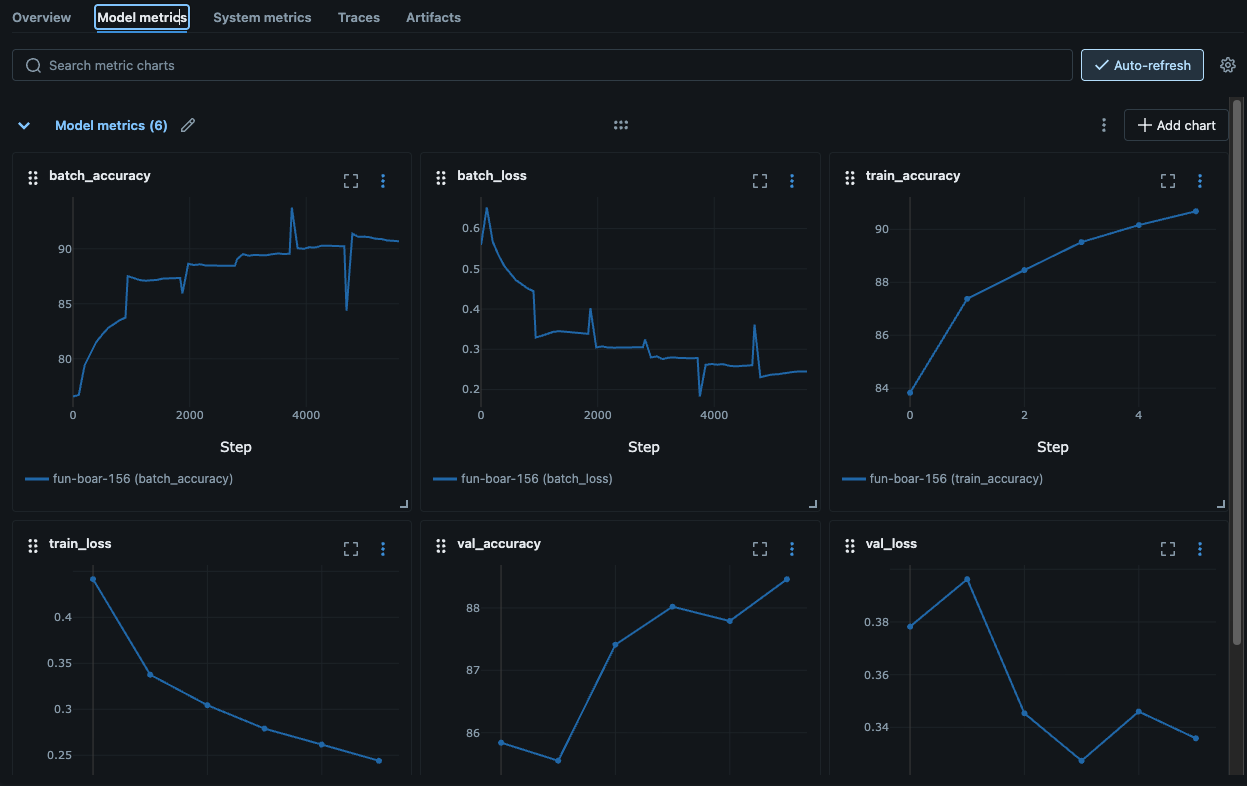

Here we swap the optimizer for Adam

### System Metrics - 5 Epochs and SGD Optimizer

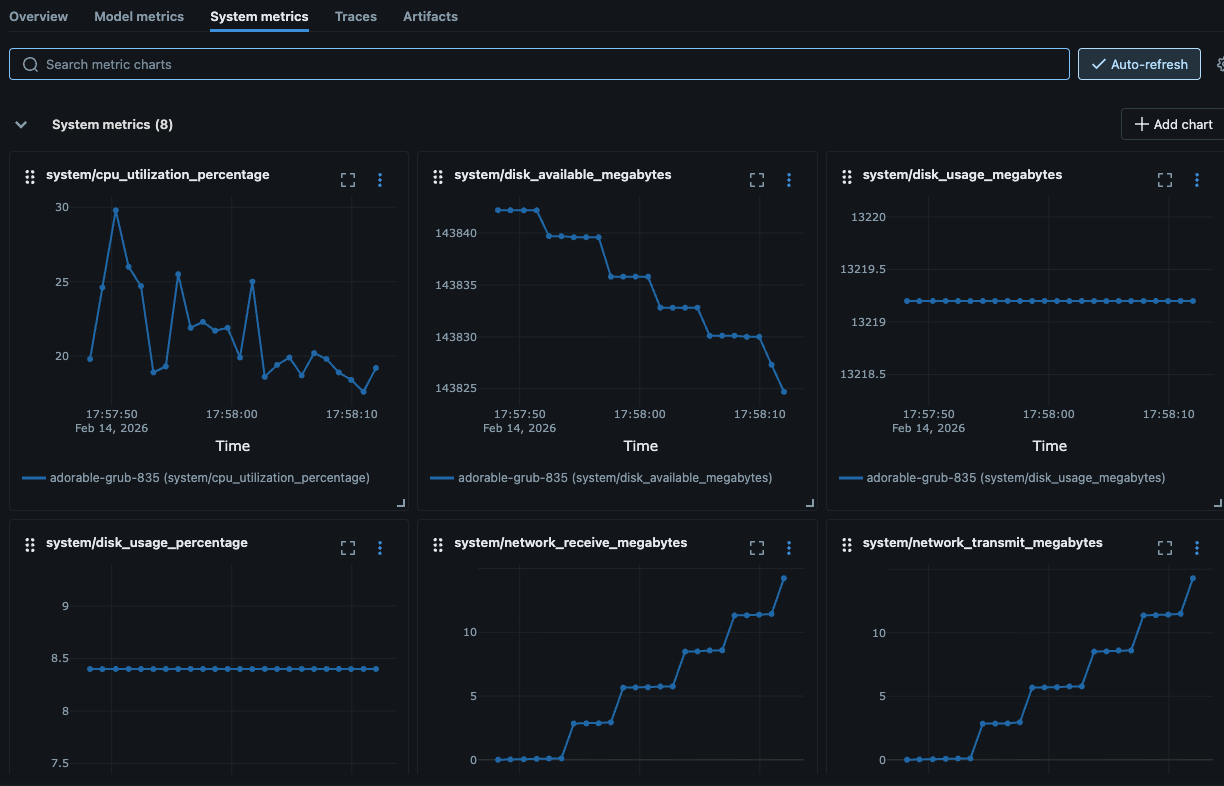

Here are some metrics like from before, except these are the system metrics to see what it looks like resource-wise

### Artifacts

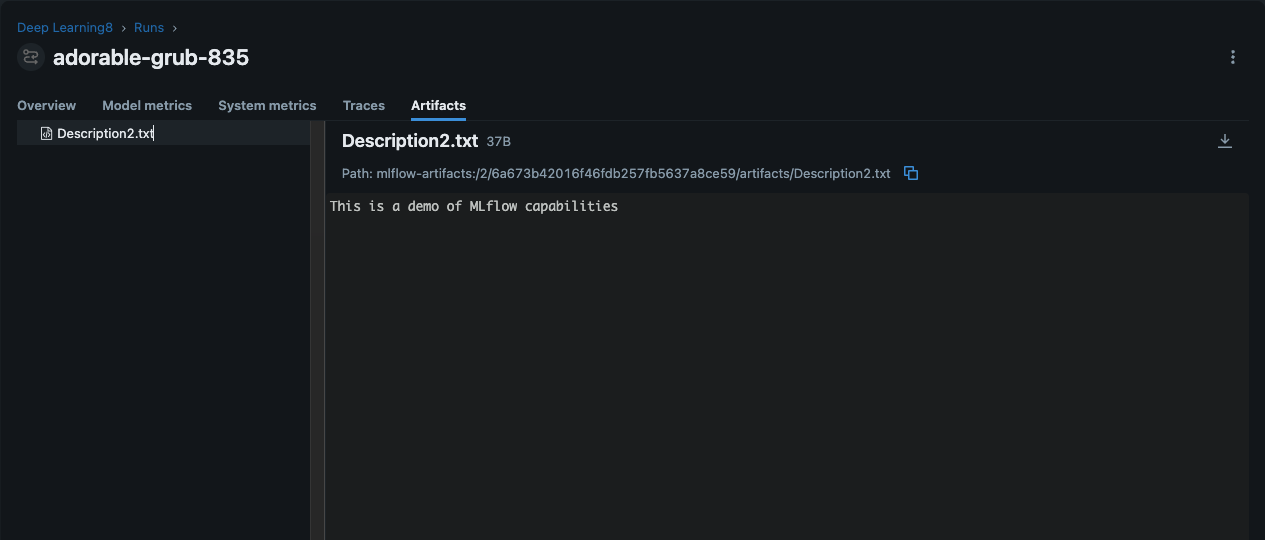

Here we have a relatively simple artifact generated, which is a text file containing a simple description

### Contents of python_env.yml and conda.yml

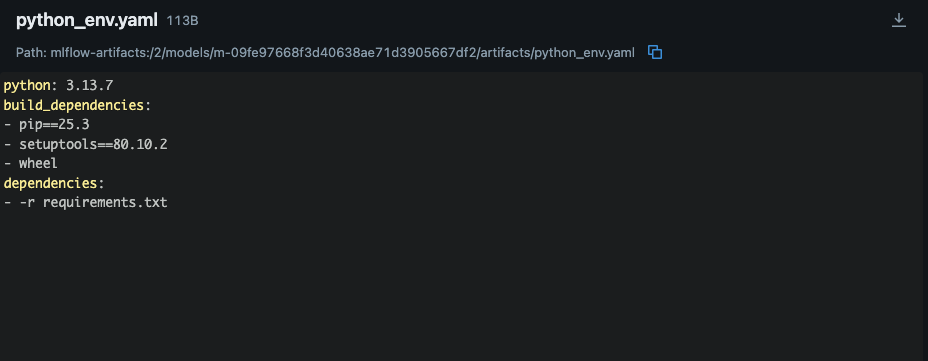
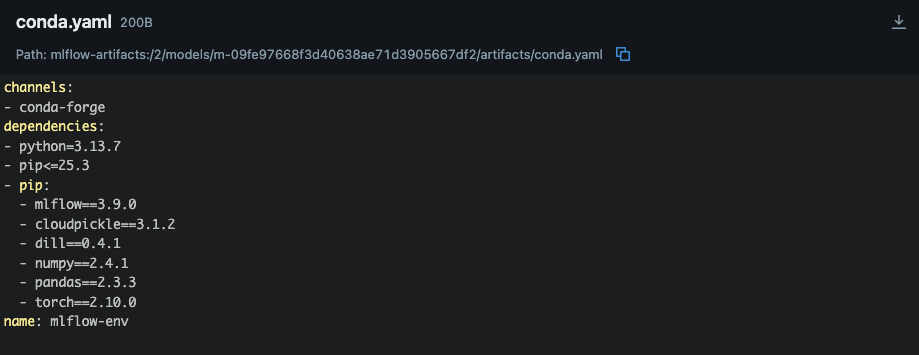

Here our `python_env.yaml` file contains:

- python version,
- build_dependencies, &
- the path for the python dependencies

While the `conda.yaml` file contains information specific to our Conda virtual environment

### Calling Model, in MLflow, from Notebook

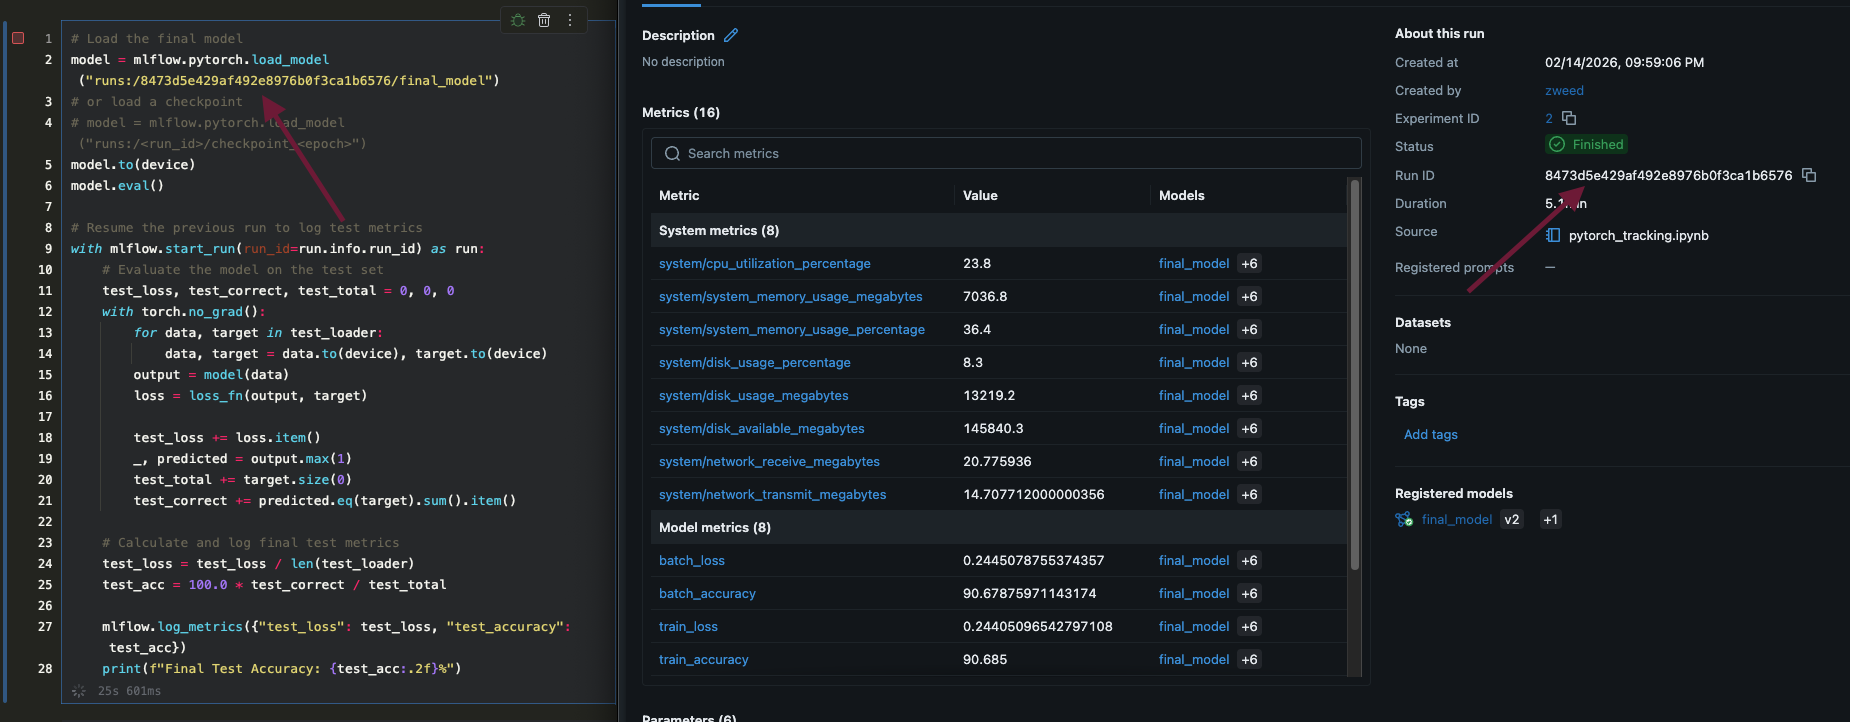

Here we identify the Unique Identifier associated with the run in mlflow, so we can load the model in our notebook.

### Describing Contents of Directory

There are a few directories and files present in the directory that the server is being run from. For example:

1. `data/`, containing the FashionMNIST dataset
2. `mlartifacts/`, containing a directory for each model run, with the model, `conda.yaml`, `python_env.yaml`, `requirements.txt`, the `model.pth` file, a serialization reference: `pickle_module_info.txt`, and a series of `Description2.txt` files
3. In the root directory, I have the SQLite database file, `mlflow.db`
4. In essence, it contains the model, artifacts, datasets, and state of the model, via `model.pth`

How that relates with what is found within the MLFlow GUI is that the what is contained in the structure is the same, and the structure its self is different. Namely:

1. What is found within `data/` and `mlartifacts` is present through models found in `Models` & `Runs` options.
2. Data from many menu options (`Runs`, `Models`, `Traces`, etc.) is present in `mlflow.db`
3. What is found within the `model.pth` file is present within `Runs` and `Models`
4. The `models/*` directory, in `mlartifacts/` contains files present within `Experiment Name` - `Models` - `Model Name` - `Artifacts`

# [Problem 2] - Monitoring Optuna with MLFlow

#### Problem Statement

You are provided with notebook named `mlflow-optuna-pytorch.ipynb`. That notebook demonstrates how to monitor OPtuna activities using MLFlow. Let the notebook run its trials. Examine the content of records stored on `mlflow` server. Manually, make a small table of the hyperparameters Optuna examined. Include training and validation accuracy and loss for all trials. Report on the optimal hyperparameters Optuna identified. Save the best model.

- Find a way to log, as some of the artifacts, the average executio time of the normal training loop with both forward and backward path and the average execution time of the forward loop used in the evaluation. You can record those times per epoch or per individual batches.
- Examine the directory from whihc you started your tracking server. Report on new contents.

### Hyperparameters Examined

| hyperparameter | range |
|----------------|-------|
| learning_rate  | 1e-4 - 1e-1|
| dropout | 0.0 - 0.9 |
| optimizer | Adam; Adadelta |

Hyperparameters that were supplied for examination by Optuna

### Training and Validation Loss

| type       | Accuracy | Loss |
|------------|----------|------|
| Train      | 100%     | 0.046281 |
| Validation | 97%      | 0.1078 |

What our resulting Accuracy and Loss metrics were for Training & Validation

### Optimal Hyper Parameters

|parameter | value |
| --- | --- |
| learning_rate | 0.0008179499 |
| dropout | 0.5 |
| optimizer | Adam|


What were found to be the optimal hyperparameters as a result of the optuna training.

### Execution Per Epoch

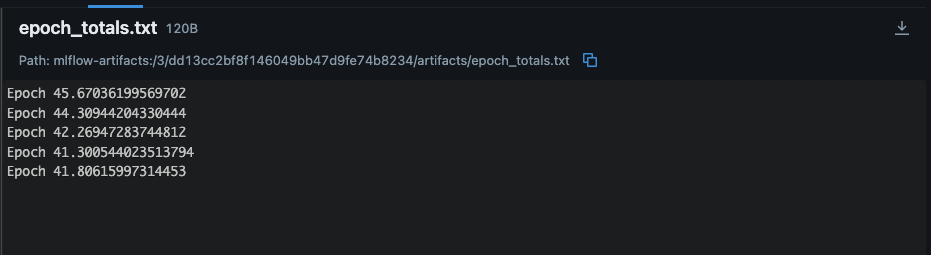

These are relatively self-explanatory and indicate how long each epoch was

### Directory Examination

Additions that were made in the directory from which `mlflow` is running include additional artifacts specifically for `epoch_totals.txt` along with additional model files for what was found in `mlflow-optuna-pytorch.ipynb`.

# [Problem 3] - Integrate MLflow and Optuna

#### Problem Statement

**Problem 3.** You are provided with another `notebook named optuna-pytorch.ipynb`. That notebook demonstrates how to monitor Optuna activities but is not instrumented with teh MLflow logging commands. Based on the code in the previous notebook, instrument this notebook so that its trials are recorded by the MLflow server. Submit a working notebook and the optimal values for the hyperparameters determined by this notebook trials.

### Including MLFlow Instrumentation in Existing Notebook

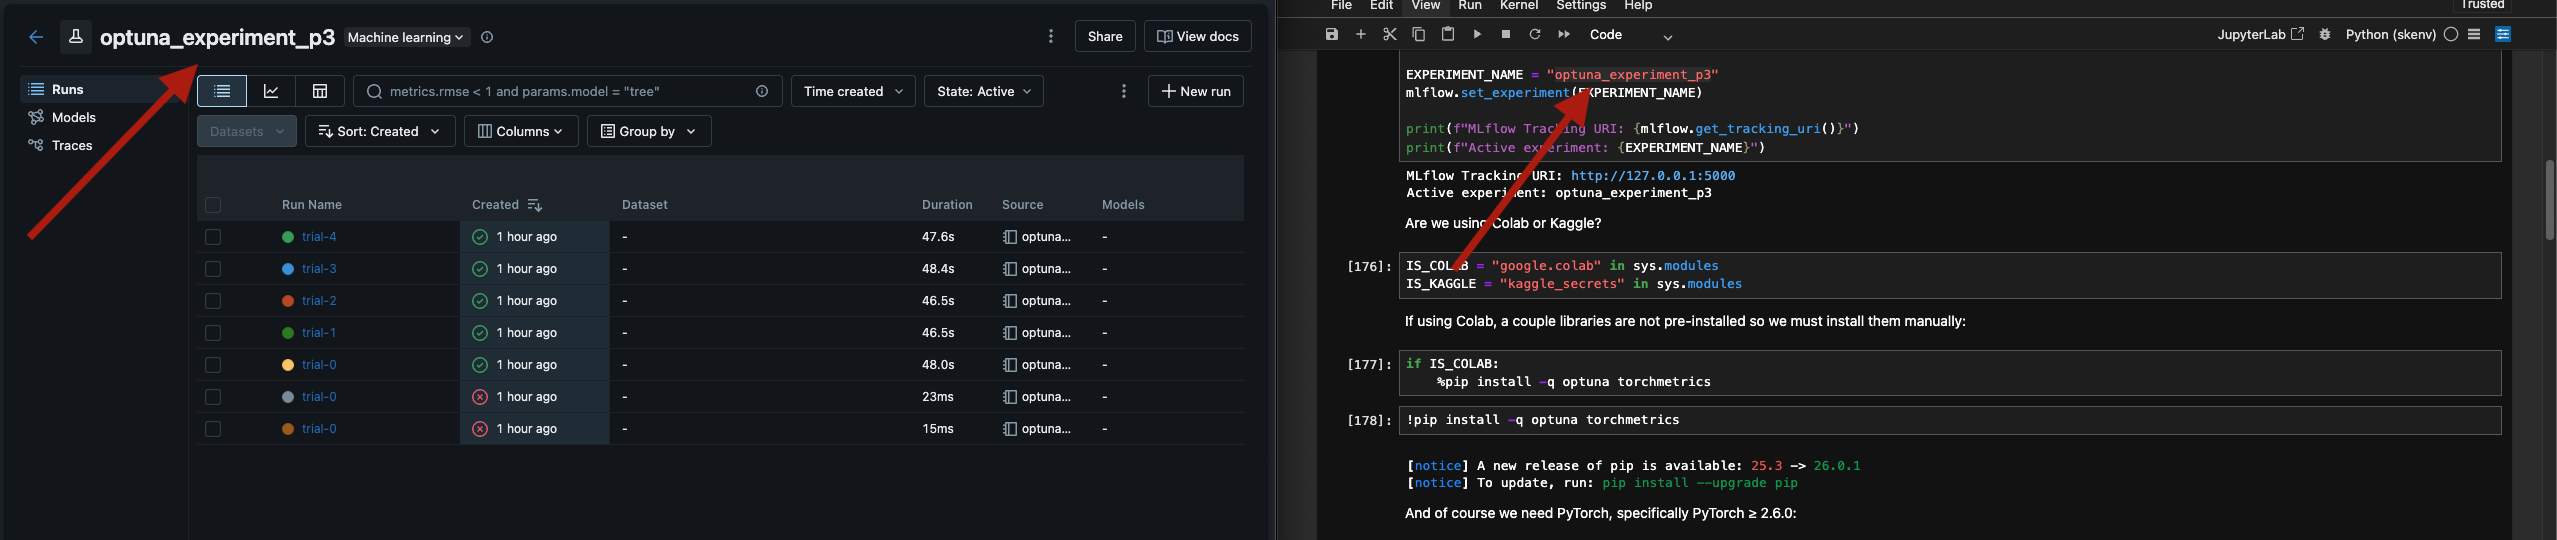

In essence, much of the work required was:

- `#set_experiment`
- wrapping the code in `#start_run`, &
- calling `#set_tags` on each epoch, with respective trial number

Screenshots below identify what this code looks like, although it is also included in the notebook

### Identifyings Runs for Each Trial Number

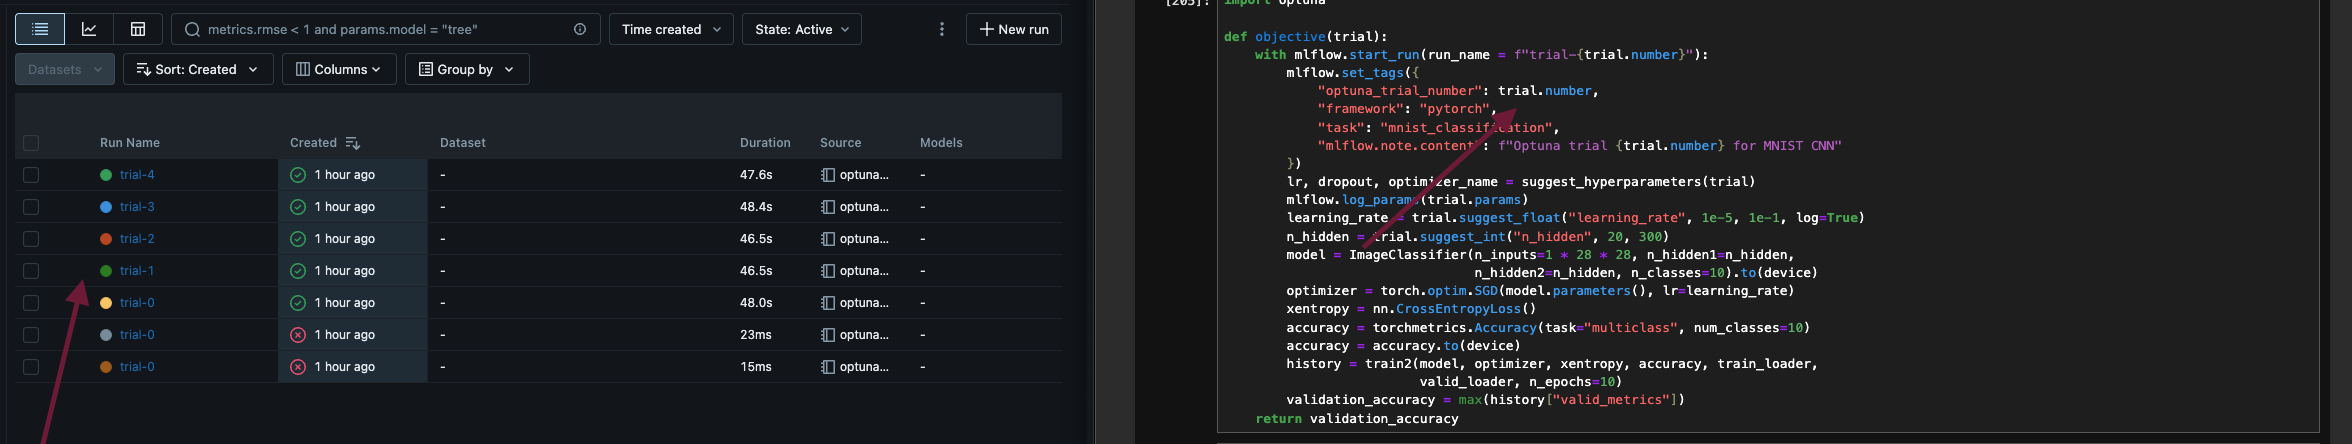

The screenshot primarily identifies how we build a list of trials in MLFlow through iterating for each Optuna trial.

### Optimal Hyperparameters

#### Trial 1
|param| value    |
|---|----------|
|learning_rate| 0.0001   |
|dropout| 0.8      |
|optimizer_name| Adadelta |

---

#### Trial 2
|param| value    |
|---|----------|
|learning_rate| 0.031    |
|dropout| 0.2      |
|optimizer_name| Adadelta |

---

#### Trial 3
|param| value |
|---|-------|
|learning_rate| 0.001 |
|dropout| 0.2   |
|optimizer_name| Adam  |



---

#### Trial 4
|param| value    |
|---|----------|
|learning_rate| 0.002    |
|dropout| 0.7      |
|optimizer_name| Adadelta |
---

Observing all trials:

- Adadelta was most frequently chosen as an optimizer
- The dropout had high variation
- Learning rate had relatively high variation as well

Given the high variation in the second and third points, it could be beneficial if we called this for more trials


# [Problem 4] - Provide Meaningful Names

#### Problem Statement

**Problem 4.** Each run in an experiment has MLflow generated names. We would like to supply more meaningful names ourselves. Please find out whether you could modify the code to accomodate this requirement. Do it while working with notebook `pytorch_tracking.ipynb`. This might have to search through the documentation. Negative response to this query, if justified, is acceptable.

In order to provide meaningful names in MLFlow runs, we can call `mlflow.set_tag("mlflow.runName", "some_name")`. [1][2]

### Bibliography

- [1] https://stackoverflow.com/a/73626675
- [2] https://github.com/mlflow/mlflow/issues/5173#issuecomment-998220604